<a href="https://colab.research.google.com/github/imaneJHX/match_outcome_predictor/blob/main/Football_Match_Outcome_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn joblib requests

In [9]:
import pandas as pd
from pathlib import Path

In [10]:
import pandas as pd

seasons = range(19, 26)
frames = []

for year in seasons:
    season = f"{year:02d}{year + 1:02d}"

    url = (
        f"https://www.football-data.co.uk/"
        f"mmz4281/{season}/E0.csv"
    )

    try:
        df = pd.read_csv(url, encoding="cp1252")
        frames.append(df)
        print(f"Season {season}: downloaded successfully")

    except Exception as error:
        print(f"Season {season}: could not download - {error}")

if not frames:
    raise RuntimeError("No data downloaded. Check your connection.")

data = pd.concat(frames, ignore_index=True)

print("Total rows:", len(data))
display(data.head())

Season 1920: downloaded successfully
Season 2021: downloaded successfully
Season 2122: downloaded successfully
Season 2223: downloaded successfully
Season 2324: downloaded successfully
Season 2425: downloaded successfully
Season 2526: downloaded successfully
Total rows: 2660


,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,BMGMCA,BVCH,BVCD,BVCA,CLCH,CLCD,CLCA,LBCH,LBCD,LBCA
0,E0,09/08/2019,20:00,Liverpool,Norwich,4,1,H,4,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,10/08/2019,12:30,West Ham,Man City,0,5,A,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,10/08/2019,15:00,Bournemouth,Sheffield United,1,1,D,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,10/08/2019,15:00,Burnley,Southampton,3,0,H,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,10/08/2019,15:00,Crystal Palace,Everton,0,0,D,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# Select only the columns needed for our project
data = data[
    ["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"]
].copy()

# Display the first five rows
display(data.head())

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR
0,09/08/2019,Liverpool,Norwich,4,1,H
1,10/08/2019,West Ham,Man City,0,5,A
2,10/08/2019,Bournemouth,Sheffield United,1,1,D
3,10/08/2019,Burnley,Southampton,3,0,H
4,10/08/2019,Crystal Palace,Everton,0,0,D


In [12]:
print(data["FTR"].value_counts())
print("\nPercentages:")
print((data["FTR"].value_counts(normalize=True) * 100).round(2))

FTR
H    1155
A     876
D     629
Name: count, dtype: int64

Percentages:
FTR
H    43.42
A    32.93
D    23.65
Name: proportion, dtype: float64


In [13]:

from collections import defaultdict, deque

# Number of previous matches used to calculate team form
LAST_N = 5

# Store each team's recent match history
history = defaultdict(lambda: deque(maxlen=LAST_N))


def calculate_form(team_history):
    """
    Calculate a team's average points,
    goals scored and goals conceded.
    """

    if len(team_history) == 0:
        return 1.0, 1.0, 1.0

    points = [match[0] for match in team_history]
    goals_scored = [match[1] for match in team_history]
    goals_conceded = [match[2] for match in team_history]

    points_avg = sum(points) / len(points)
    goals_scored_avg = sum(goals_scored) / len(goals_scored)
    goals_conceded_avg = sum(goals_conceded) / len(goals_conceded)

    return points_avg, goals_scored_avg, goals_conceded_avg


In [14]:

# Start with an empty history for every team
history = defaultdict(lambda: deque(maxlen=LAST_N))

features = []
targets = []

# Process matches from oldest to newest
for match in data.itertuples(index=False):

    home = match.HomeTeam
    away = match.AwayTeam

    # Calculate form BEFORE the current match
    home_form = calculate_form(history[home])
    away_form = calculate_form(history[away])

    # Store the six input features
    features.append({
        "home_points_avg": home_form[0],
        "home_goals_scored_avg": home_form[1],
        "home_goals_conceded_avg": home_form[2],

        "away_points_avg": away_form[0],
        "away_goals_scored_avg": away_form[1],
        "away_goals_conceded_avg": away_form[2],
    })

    # Store the result we want to predict
    targets.append(match.FTR)

    home_goals = int(match.FTHG)
    away_goals = int(match.FTAG)

    # Calculate points earned by each team
    if home_goals > away_goals:
        home_points, away_points = 3, 0
    elif home_goals < away_goals:
        home_points, away_points = 0, 3
    else:
        home_points, away_points = 1, 1

    # Update history AFTER the current match
    history[home].append(
        (home_points, home_goals, away_goals)
    )

    history[away].append(
        (away_points, away_goals, home_goals)
    )

# Convert the features and targets into Pandas objects
X = pd.DataFrame(features)
y = pd.Series(targets, name="result")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())


Features shape: (2660, 6)
Target shape: (2660,)


,home_points_avg,home_goals_scored_avg,home_goals_conceded_avg,away_points_avg,away_goals_scored_avg,away_goals_conceded_avg
0,1.0,1.0,1.0,1.0,1.0,1.0
1,1.0,1.0,1.0,1.0,1.0,1.0
2,1.0,1.0,1.0,1.0,1.0,1.0
3,1.0,1.0,1.0,1.0,1.0,1.0
4,1.0,1.0,1.0,1.0,1.0,1.0


,result
0,H
1,A
2,D
3,H
4,D


In [16]:
# Display matches from later in the dataset
display(X.iloc[10:15])

# Check how much each feature varies
print(X.nunique())

,home_points_avg,home_goals_scored_avg,home_goals_conceded_avg,away_points_avg,away_goals_scored_avg,away_goals_conceded_avg
10,3.0,1.0,0.0,3.0,3.0,0.0
11,0.0,1.0,3.0,1.0,1.0,1.0
12,3.0,3.0,0.0,0.0,0.0,5.0
13,1.0,0.0,0.0,0.0,0.0,3.0
14,0.0,1.0,4.0,0.0,0.0,1.0


home_points_avg            23
home_goals_scored_avg      36
home_goals_conceded_avg    33
away_points_avg            22
away_goals_scored_avg      33
away_goals_conceded_avg    38
dtype: int64


In [17]:
# Define the split point: 80% for training
split_index = int(len(X) * 0.80)

# Create training and testing sets
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Display the dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

# Check the date ranges
print("\nTraining period:")
print(data["Date"].iloc[0], "to", data["Date"].iloc[split_index - 1])

print("\nTesting period:")
print(data["Date"].iloc[split_index], "to", data["Date"].iloc[-1])

Training features: (2128, 6)
Testing features: (532, 6)
Training targets: (2128,)
Testing targets: (532,)

Training period:
09/08/2019 to 26/01/2025

Testing period:
26/01/2025 to 24/05/2026


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create the Machine Learning pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train the model using historical matches
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


Explanation
1. LogisticRegression
This is our first predictive algorithm. Although its name contains "regression", it can be used for classification.
2. StandardScaler()
This standardizes the numerical features so that they have comparable scales. For example, average goals and average points have different numerical ranges.
3. Pipeline([...])
A pipeline combines preprocessing and the model into one object. When we train it, the scaler learns from the training set only, avoiding the use of test-set statistics.
4. model.fit(X_train, y_train)
This is where the learning happens. The model uses the six features in X_train and their corresponding match outcomes in y_train to learn patterns.

In [19]:

# Predict the outcomes of the test matches
y_pred = model.predict(X_test)

# Display a few real and predicted outcomes
comparison = pd.DataFrame({
    "Actual result": y_test.values,
    "Predicted result": y_pred
})

display(comparison.head(10))


,Actual result,Predicted result
0,A,H
1,H,H
2,A,H
3,H,H
4,A,H
5,A,H
6,H,A
7,A,H
8,A,A
9,H,A


In [21]:

from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(f"Model accuracy: {accuracy:.2%}")


Model accuracy: 48.31%


In [22]:

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        labels=["H", "D", "A"],
        target_names=[
            "Home win",
            "Draw",
            "Away win"
        ],
        zero_division=0
    )
)


              precision    recall  f1-score   support

    Home win       0.50      0.76      0.60       228
        Draw       0.00      0.00      0.00       136
    Away win       0.46      0.50      0.48       168

    accuracy                           0.48       532
   macro avg       0.32      0.42      0.36       532
weighted avg       0.36      0.48      0.41       532



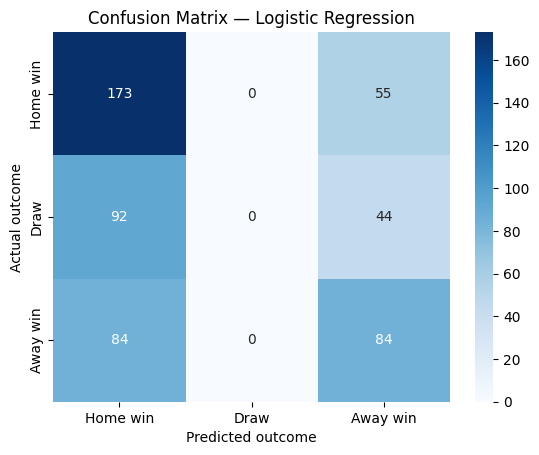

In [23]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["H", "D", "A"]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Home win", "Draw", "Away win"],
    yticklabels=["Home win", "Draw", "Away win"]
)

plt.xlabel("Predicted outcome")
plt.ylabel("Actual outcome")
plt.title("Confusion Matrix — Logistic Regression")
plt.show()


In [24]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict the test outcomes
rf_predictions = rf_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_predictions)

print(f"Random Forest accuracy: {rf_accuracy:.2%}")


Random Forest accuracy: 41.35%


In [25]:

import pandas as pd

comparison_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, model.predict(X_test)),
        accuracy_score(y_test, rf_model.predict(X_test))
    ]
})

comparison_results["Accuracy (%)"] = (
    comparison_results["Accuracy"] * 100
).round(2)

display(
    comparison_results.sort_values(
        "Accuracy",
        ascending=False
    )
)


,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.483083,48.31
1,Random Forest,0.413534,41.35


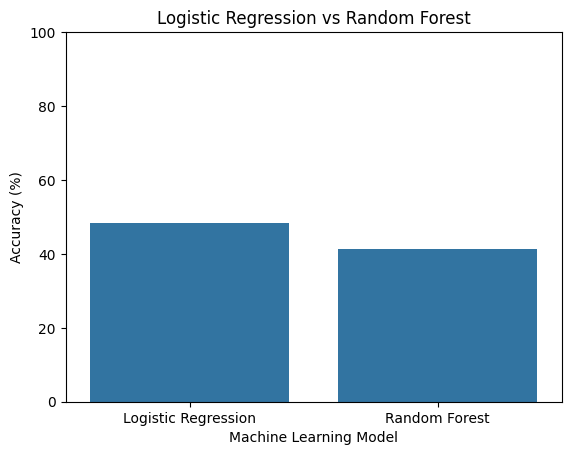

In [26]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(
    data=comparison_results,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Logistic Regression vs Random Forest")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 100)
plt.show()


In [27]:

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        rf_predictions,
        labels=["H", "D", "A"],
        target_names=[
            "Home win",
            "Draw",
            "Away win"
        ],
        zero_division=0
    )
)


              precision    recall  f1-score   support

    Home win       0.51      0.54      0.52       228
        Draw       0.20      0.15      0.17       136
    Away win       0.41      0.46      0.43       168

    accuracy                           0.41       532
   macro avg       0.37      0.38      0.37       532
weighted avg       0.40      0.41      0.40       532



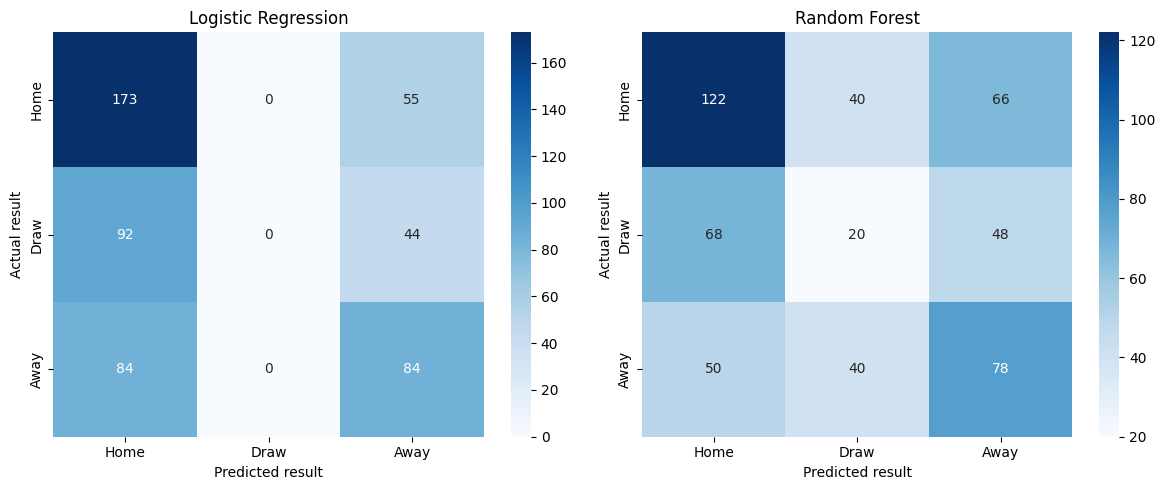

In [28]:

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

predictions_by_model = {
    "Logistic Regression": model.predict(X_test),
    "Random Forest": rf_predictions
}

for ax, (name, predictions) in zip(
    axes,
    predictions_by_model.items()
):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["H", "D", "A"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Home", "Draw", "Away"],
        yticklabels=["Home", "Draw", "Away"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted result")
    ax.set_ylabel("Actual result")

plt.tight_layout()
plt.show()


In [29]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report
)

# Create a new Logistic Regression model
balanced_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

# Train the new model
balanced_model.fit(X_train, y_train)

# Predict the test results
balanced_predictions = balanced_model.predict(X_test)

# Evaluate the model
print(
    "Accuracy:",
    round(accuracy_score(y_test, balanced_predictions) * 100, 2),
    "%"
)

print(
    "Balanced accuracy:",
    round(
        balanced_accuracy_score(y_test, balanced_predictions) * 100,
        2
    ),
    "%"
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        balanced_predictions,
        labels=["H", "D", "A"],
        target_names=["Home win", "Draw", "Away win"],
        zero_division=0
    )
)


Accuracy: 43.98 %
Balanced accuracy: 41.39 %

Classification report:
              precision    recall  f1-score   support

    Home win       0.52      0.52      0.52       228
        Draw       0.27      0.18      0.21       136
    Away win       0.42      0.55      0.48       168

    accuracy                           0.44       532
   macro avg       0.41      0.41      0.40       532
weighted avg       0.43      0.44      0.43       532



In [30]:
%pip install -q plotly

In [31]:

import pandas as pd
import plotly.express as px

# Combine the features and actual match outcomes
viz_data = X.copy()
viz_data["result"] = y.values

# Make the outcome names easier to understand
viz_data["result"] = viz_data["result"].map({
    "H": "Home win",
    "D": "Draw",
    "A": "Away win"
})

# Create an interactive 3D scatter plot
fig = px.scatter_3d(
    viz_data,
    x="home_points_avg",
    y="away_points_avg",
    z="home_goals_scored_avg",
    color="result",
    color_discrete_map={
        "Home win": "#22C55E",
        "Draw": "#F59E0B",
        "Away win": "#3B82F6"
    },
    opacity=0.7,
    title="3D Visualization of Football Match Outcomes",
    labels={
        "home_points_avg": "Home Team Average Points",
        "away_points_avg": "Away Team Average Points",
        "home_goals_scored_avg": "Home Team Average Goals Scored",
        "result": "Actual Match Outcome"
    },
    hover_data=["home_goals_conceded_avg",
                "away_goals_scored_avg",
                "away_goals_conceded_avg"]
)

fig.update_traces(marker=dict(size=4))

fig.update_layout(
    scene=dict(
        xaxis_title="Home Team Form",
        yaxis_title="Away Team Form",
        zaxis_title="Home Goals Scored"
    ),
    width=950,
    height=700
)

fig.show()


In [32]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# 1. Define the two features for our 3D visualization
home_form = np.linspace(
    X["home_points_avg"].min(),
    X["home_points_avg"].max(),
    35
)

away_form = np.linspace(
    X["away_points_avg"].min(),
    X["away_points_avg"].max(),
    35
)

HOME, AWAY = np.meshgrid(home_form, away_form)

# 2. Keep the other features at their average values
features = pd.DataFrame({
    "home_points_avg": HOME.ravel(),
    "home_goals_scored_avg": X["home_goals_scored_avg"].mean(),
    "home_goals_conceded_avg": X["home_goals_conceded_avg"].mean(),
    "away_points_avg": AWAY.ravel(),
    "away_goals_scored_avg": X["away_goals_scored_avg"].mean(),
    "away_goals_conceded_avg": X["away_goals_conceded_avg"].mean()
})

# 3. Calculate the probability of a home victory
probabilities = model.predict_proba(features)

home_class_index = list(model.classes_).index("H")

Z = probabilities[:, home_class_index].reshape(HOME.shape)

# 4. Create the futuristic 3D surface
fig = go.Figure()

fig.add_trace(go.Surface(
    x=HOME,
    y=AWAY,
    z=Z,
    colorscale=[
        [0.0, "#180510"],
        [0.3, "#780018"],
        [0.65, "#ff1738"],
        [1.0, "#ff625c"]
    ],
    showscale=False,
    opacity=0.95,
    lighting=dict(
        ambient=0.35,
        diffuse=0.8,
        specular=1.0,
        roughness=0.25,
        fresnel=0.5
    ),
    lightposition=dict(x=100, y=200, z=300),
    hovertemplate=(
        "Home form: %{x:.2f}<br>"
        "Away form: %{y:.2f}<br>"
        "Home win probability: %{z:.1%}"
        "<extra></extra>"
    )
))

# 5. Add a cyan wireframe over the surface
for i in range(HOME.shape[0]):
    fig.add_trace(go.Scatter3d(
        x=HOME[i, :],
        y=AWAY[i, :],
        z=Z[i, :],
        mode="lines",
        line=dict(color="#48ffff", width=2),
        opacity=0.8,
        showlegend=False,
        hoverinfo="skip"
    ))

for j in range(HOME.shape[1]):
    fig.add_trace(go.Scatter3d(
        x=HOME[:, j],
        y=AWAY[:, j],
        z=Z[:, j],
        mode="lines",
        line=dict(color="#48ffff", width=2),
        opacity=0.8,
        showlegend=False,
        hoverinfo="skip"
    ))

# 6. Apply the dark, futuristic design
fig.update_layout(
    title=dict(
        text="FOOTBALL AI | 3D PREDICTION SURFACE",
        font=dict(color="#48ffff", size=22),
        x=0.5
    ),
    paper_bgcolor="#080810",
    font=dict(color="white"),
    width=1000,
    height=750,
    margin=dict(l=0, r=0, t=80, b=0),
    scene=dict(
        bgcolor="#080810",
        xaxis=dict(
            title="Home Team Form",
            color="#48ffff",
            gridcolor="#164d55",
            zerolinecolor="#48ffff",
            showbackground=False
        ),
        yaxis=dict(
            title="Away Team Form",
            color="#48ffff",
            gridcolor="#164d55",
            zerolinecolor="#48ffff",
            showbackground=False
        ),
        zaxis=dict(
            title="Home Win Probability",
            color="#48ffff",
            gridcolor="#164d55",
            range=[0, 1],
            tickformat=".0%",
            showbackground=False
        ),
        camera=dict(
            eye=dict(x=1.5, y=-1.8, z=1.2)
        ),
        aspectmode="manual",
        aspectratio=dict(x=1.2, y=1.2, z=0.7)
    )
)

fig.show()